# 01 — Dataset Inspection

## Objectives

- Verify the Python environment and GPU availability.
- Inspect the original fruit dataset.
- Verify the fixed training, validation and test split.
- Check image integrity and dimensions.
- Visualize fresh and rotten fruit samples.
- Identify variations in illumination, colour and appearance.


## 1. Imports and environment

Select the **Python (fruit-split)** kernel. This notebook requires NumPy, pandas,
Matplotlib, Pillow and IPython. PyTorch is optional: dataset inspection runs on the CPU.

If setting up this environment again, run these commands in a terminal:

    conda install -n fruit-split --override-channels -c defaults pillow matplotlib-base ipykernel
    conda run -n fruit-split python -m ipykernel install --user --name fruit-split --display-name "Python (fruit-split)"

The default-channel builds were checked on this Windows machine after other builds
were blocked by Smart App Control. No GPU is needed for this notebook.


In [1]:
import hashlib
import os
import platform
import sys
import warnings
from importlib import metadata
from pathlib import Path

import matplotlib
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image, ImageOps

SEED = 42
FRUITS = [
    "apple", "banana", "grape", "guava",
    "jujube", "orange", "pomegranate", "strawberry",
]
LABEL_NAMES = {0: "fresh", 1: "rotten"}
SPLITS = ["train", "val", "test"]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
COLOURS = {"fresh": "#2f855a", "rotten": "#c05640"}
THUMBNAIL_SIZE = (128, 128)

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 100)

print("Python:", platform.python_version())
print("Executable:", sys.executable)
print("Working directory:", Path.cwd())
display(pd.DataFrame(
    [(name, metadata.version(name)) for name in
     ["numpy", "pandas", "matplotlib", "Pillow", "ipykernel"]],
    columns=["package", "version"],
))

# CUDA availability describes this PyTorch installation, not every possible GPU.
try:
    import torch
    print("PyTorch:", torch.__version__)
    if torch.version.cuda is None:
        print("GPU check: CPU-only PyTorch build; CUDA cannot be used by this build.")
    elif torch.cuda.is_available():
        print("CUDA devices:", torch.cuda.device_count())
        for device in range(torch.cuda.device_count()):
            print(f"  {device}: {torch.cuda.get_device_name(device)}")
    else:
        print("GPU check: CUDA-enabled PyTorch, but no usable CUDA device was detected.")
except Exception as exc:
    print(f"GPU check unavailable: {type(exc).__name__}: {exc}")
    print("PyTorch is optional here; the remaining inspection uses the CPU.")


Python: 3.11.18
Executable: C:\Users\majah\miniconda3\envs\fruit-split\python.exe
Working directory: C:\Users\majah\Local Data\NDHU\YEAR 4\Semester 1\Intro to img Processing\PROJECT_ImgProcessing\fruit-illum-norm\notebooks


,package,version
0,numpy,2.4.6
1,pandas,3.1.0
2,matplotlib,3.11.2
3,Pillow,13.0.0
4,ipykernel,7.3.0


GPU check unavailable: ModuleNotFoundError: No module named 'torch'
PyTorch is optional here; the remaining inspection uses the CPU.


## 2. Load dataset manifest

Load the existing fixed split from **data/splits/split_seed42.csv**. Image paths in
the manifest are relative to the repository root. Root discovery supports starting
Jupyter from the repository root, the notebooks directory, or another directory inside
this repository.

This notebook reads the manifest and images; it does not regenerate the split or
change any original image.


In [2]:
def find_repository_root(start):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src" / "data" / "make_split.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from inside the fruit-illum-norm repository.")


REPO_ROOT = find_repository_root(Path.cwd())
MANIFEST_PATH = REPO_ROOT / "data" / "splits" / "split_seed42.csv"
RAW_ROOT = REPO_ROOT / "data" / "raw"
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f"Manifest not found: {MANIFEST_PATH}\n"
        "From the repository root, run: python src/data/make_split.py --root data/raw --seed 42"
    )

df = pd.read_csv(MANIFEST_PATH)
REQUIRED_COLUMNS = ["path", "label", "fruit", "cls", "split"]
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
if missing_columns:
    raise ValueError(f"The manifest is missing columns: {missing_columns}")
if df.empty:
    raise ValueError("The manifest contains no image rows.")


def resolve_image_path(value):
    if pd.isna(value) or not str(value).strip():
        return None
    path = Path(str(value))
    return (path if path.is_absolute() else REPO_ROOT / path).resolve()


def path_key(path):
    return os.path.normcase(str(path)) if path is not None else None


df["_image_path"] = df["path"].map(resolve_image_path)
df["_path_key"] = df["_image_path"].map(path_key)
print("Repository:", REPO_ROOT)
print("Manifest:", MANIFEST_PATH.relative_to(REPO_ROOT))
print(f"Rows: {len(df):,}")
display(df[REQUIRED_COLUMNS].head())


Repository: C:\Users\majah\Local Data\NDHU\YEAR 4\Semester 1\Intro to img Processing\PROJECT_ImgProcessing\fruit-illum-norm
Manifest: data\splits\split_seed42.csv
Rows: 3,200


,path,label,fruit,cls,split
0,data/raw/Original Image/FreshApple/FreshApple (1).jpg,0,apple,fresh_apple,train
1,data/raw/Original Image/FreshApple/FreshApple (10).jpg,0,apple,fresh_apple,val
2,data/raw/Original Image/FreshApple/FreshApple (100).jpg,0,apple,fresh_apple,train
3,data/raw/Original Image/FreshApple/FreshApple (101).jpg,0,apple,fresh_apple,train
4,data/raw/Original Image/FreshApple/FreshApple (102).jpg,0,apple,fresh_apple,train


## 3. Dataset verification

Check the schema, binary labels (**0 = fresh, 1 = rotten**), fruit and class names,
file existence, repeated paths, and coverage of the original files.

SHA-256 identifies **byte-identical files**, including copies with different filenames.
Cross-split duplicates are a leakage warning. They are reported without stopping the
rest of the inspection. This check does not identify every re-encoded or near-duplicate
photograph, or images of the same physical fruit captured separately.


In [3]:
df["state"] = df["label"].map(LABEL_NAMES)
expected_classes = {f"{state}_{fruit}" for state in LABEL_NAMES.values() for fruit in FRUITS}
expected_cls = df["state"].astype("string") + "_" + df["fruit"].astype("string")
schema_checks = pd.Series({
    "Required fields are populated": not df[REQUIRED_COLUMNS].isna().any().any(),
    "Paths are non-empty": df["_image_path"].notna().all(),
    "Labels are 0 or 1": df["label"].isin(LABEL_NAMES).all(),
    "Exactly the eight expected fruits": set(df["fruit"]) == set(FRUITS),
    "Exactly the sixteen expected classes": set(df["cls"]) == expected_classes,
    "Class agrees with label and fruit": df["cls"].eq(expected_cls).fillna(False).all(),
    "Exactly train, val and test splits": set(df["split"]) == set(SPLITS),
    "No augmented paths": not df["path"].astype("string").str.contains("augment", case=False).any(),
}, name="passed")
display(schema_checks.to_frame())
if not schema_checks.all():
    raise ValueError("Resolve the failed manifest/schema checks before interpreting the following analyses.")

df["_exists"] = df["_image_path"].map(lambda path: path.is_file())
missing_paths = df.loc[~df["_exists"], REQUIRED_COLUMNS]
repeated_paths = df.loc[df["_path_key"].duplicated(keep=False), REQUIRED_COLUMNS]

disk_paths = {
    path_key(path.resolve())
    for path in RAW_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in EXTENSIONS
    and "augment" not in path.relative_to(RAW_ROOT).as_posix().lower()
}
unlisted_paths = sorted(disk_paths - set(df["_path_key"]))
print("Missing image files:", len(missing_paths))
print("Rows with repeated resolved paths:", len(repeated_paths))
print("Original image files absent from the manifest:", len(unlisted_paths))
for table in (missing_paths, repeated_paths):
    if not table.empty:
        display(table)
if unlisted_paths:
    display(pd.DataFrame({"unlisted_file": unlisted_paths}).head(20))

hash_errors = []
file_hashes = {}
for path in df.loc[df["_exists"], "_image_path"].drop_duplicates():
    try:
        with path.open("rb") as handle:
            digest = hashlib.sha256()
            for chunk in iter(lambda: handle.read(1024 * 1024), b""):
                digest.update(chunk)
        file_hashes[path_key(path)] = digest.hexdigest()
    except OSError as exc:
        hash_errors.append({"path": str(path), "error": str(exc)})

df["sha256"] = df["_path_key"].map(file_hashes)
duplicate_rows = df.loc[
    df["sha256"].notna() & df["sha256"].duplicated(keep=False),
    ["sha256", *REQUIRED_COLUMNS],
].copy()
duplicate_summary = duplicate_rows.groupby("sha256").agg(
    files=("path", "size"),
    split_count=("split", "nunique"),
    splits=("split", lambda values: ", ".join(sorted(set(values)))),
    filenames=("path", lambda values: " | ".join(Path(value).name for value in values)),
)
leaking_hashes = set(duplicate_summary.index[duplicate_summary["split_count"].gt(1)])
leakage_rows = duplicate_rows.loc[duplicate_rows["sha256"].isin(leaking_hashes)].copy()

print(f"Unique byte contents: {df['sha256'].nunique():,} / {len(df):,} manifest rows")
print("Exact duplicate groups:", len(duplicate_summary))
print("Duplicate groups spanning splits:", len(leaking_hashes))
if not duplicate_summary.empty:
    display(duplicate_summary.rename_axis("sha256").reset_index().assign(
        hash_id=lambda table: table["sha256"].str[:12]
    )[["hash_id", "files", "splits", "filenames"]])
if not leakage_rows.empty:
    display(leakage_rows.assign(filename=lambda table: table["path"].map(lambda value: Path(value).name))
            [["filename", "fruit", "split"]])
    warnings.warn(
        "Identical image contents occur in different splits. Resolve duplicate grouping "
        "before using this split for final model evaluation.",
        UserWarning,
    )
if hash_errors:
    display(pd.DataFrame(hash_errors))


,passed
Required fields are populated,True
Paths are non-empty,True
Labels are 0 or 1,True
Exactly the eight expected fruits,True
Exactly the sixteen expected classes,True
Class agrees with label and fruit,True
"Exactly train, val and test splits",True
No augmented paths,True


Missing image files: 0
Rows with repeated resolved paths: 0
Original image files absent from the manifest: 0


Unique byte contents: 3,193 / 3,200 manifest rows
Exact duplicate groups: 7
Duplicate groups spanning splits: 2


,hash_id,files,splits,filenames
0,06b36854bce6,2,train,FreshOrange (167).jpg | FreshOrange (62).jpg
1,0a5a90723e33,2,"test, val",FreshOrange (75).jpg | FreshOrange (88).jpg
2,2311566fd04f,2,train,FreshOrange (27).jpg | FreshOrange (77).jpg
3,27d2a953f6ad,2,train,FreshOrange (168).jpg | FreshOrange (63).jpg
4,5cfefbb3e4bc,2,train,FreshOrange (65).jpg | FreshOrange (78).jpg
5,6393fcba5db8,2,"test, train",FreshOrange (74).jpg | FreshOrange (87).jpg
6,e5f34ce96d79,2,train,FreshOrange (66).jpg | FreshOrange (79).jpg


,filename,fruit,split
1172,FreshOrange (74).jpg,orange,train
1173,FreshOrange (75).jpg,orange,test
1186,FreshOrange (87).jpg,orange,test
1187,FreshOrange (88).jpg,orange,val


C:\Users\majah\AppData\Local\Temp\ipykernel_20056\1479213269.py:74: UserWarning: Identical image contents occur in different splits. Resolve duplicate grouping before using this split for final model evaluation.
  warnings.warn(


## 4. Class distribution

Compare the binary freshness labels, each fruit, and all sixteen fruit/state classes.
The current dataset is expected to contain **3,200 files**, with **200 per class**.
Balanced file counts alone do not establish that the photographs are independent.


,images
state,
fresh,1600
rotten,1600


state,fresh,rotten,total
fruit,,,
apple,200,200,400
banana,200,200,400
grape,200,200,400
guava,200,200,400
jujube,200,200,400
orange,200,200,400
pomegranate,200,200,400
strawberry,200,200,400


Expected total of 3,200: True
Every class has 200 images: True


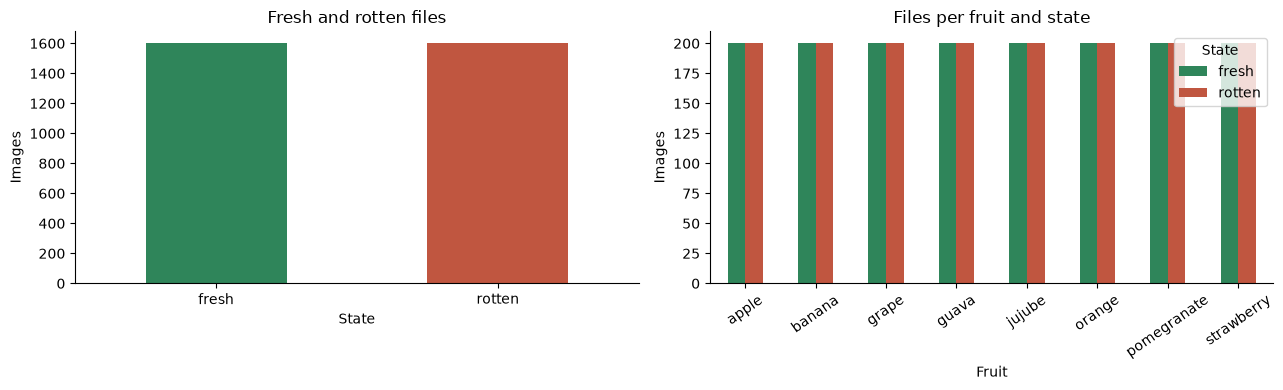

In [4]:
state_counts = df["state"].value_counts().reindex(LABEL_NAMES.values(), fill_value=0)
fruit_state_counts = pd.crosstab(df["fruit"], df["state"]).reindex(
    index=FRUITS, columns=list(LABEL_NAMES.values()), fill_value=0
)
class_counts = df["cls"].value_counts().reindex(sorted(expected_classes), fill_value=0)
display(state_counts.rename_axis("state").to_frame("images"))
display(fruit_state_counts.assign(total=fruit_state_counts.sum(axis=1)))
print("Expected total of 3,200:", len(df) == 3200)
print("Every class has 200 images:", class_counts.eq(200).all())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
state_counts.plot.bar(ax=axes[0], color=[COLOURS[state] for state in state_counts.index], rot=0)
axes[0].set(title="Fresh and rotten files", xlabel="State", ylabel="Images")
fruit_state_counts.plot.bar(ax=axes[1], color=list(COLOURS.values()), rot=35)
axes[1].set(title="Files per fruit and state", xlabel="Fruit", ylabel="Images")
axes[1].legend(title="State")
fig.tight_layout()
plt.show()


## 5. Split distribution

Verify the intended **80% / 10% / 10%** training, validation and test proportions.
For 200 files per class, the expected allocation is **160 / 20 / 20 per class**,
or **2,560 / 320 / 320** in total. These tables describe the existing CSV.


,images,fraction,expected_images,matches_expected
split,,,,
train,2560,0.8,2560,True
val,320,0.1,320,True
test,320,0.1,320,True


state,fresh,rotten
split,,
train,1280,1280
val,160,160
test,160,160


split,train,val,test
cls,,,
fresh_apple,160,20,20
fresh_banana,160,20,20
fresh_grape,160,20,20
fresh_guava,160,20,20
fresh_jujube,160,20,20
fresh_orange,160,20,20
fresh_pomegranate,160,20,20
fresh_strawberry,160,20,20
rotten_apple,160,20,20


Every class matches 160 / 20 / 20: True


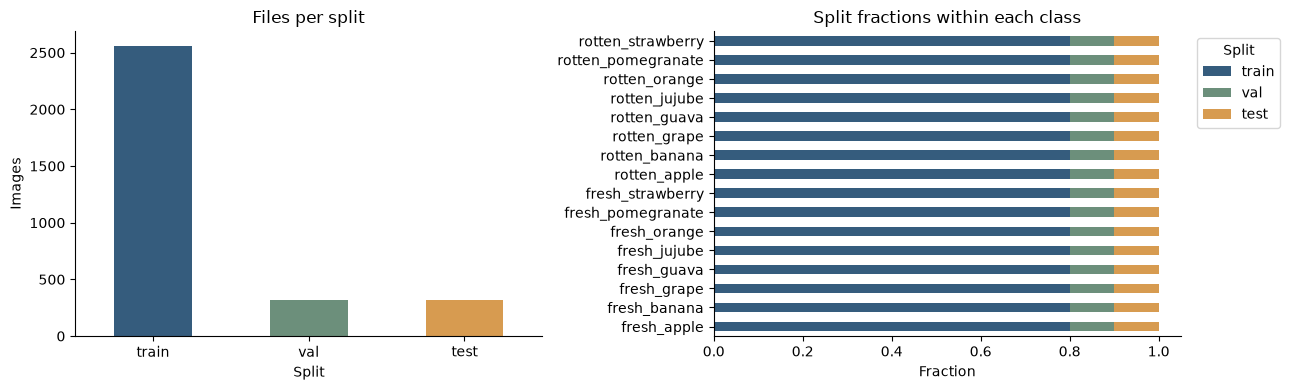

In [5]:
split_counts = df["split"].value_counts().reindex(SPLITS, fill_value=0)
split_summary = pd.DataFrame({
    "images": split_counts,
    "fraction": split_counts / len(df),
    "expected_images": [2560, 320, 320],
})
split_summary["matches_expected"] = split_summary["images"].eq(split_summary["expected_images"])
class_split_counts = pd.crosstab(df["cls"], df["split"]).reindex(
    index=sorted(expected_classes), columns=SPLITS, fill_value=0
)
state_split_counts = pd.crosstab(df["split"], df["state"]).reindex(
    index=SPLITS, columns=list(LABEL_NAMES.values()), fill_value=0
)
expected_per_class = pd.Series({"train": 160, "val": 20, "test": 20})
split_balance_ok = class_split_counts.eq(expected_per_class, axis="columns").all().all()

display(split_summary)
display(state_split_counts)
display(class_split_counts)
print("Every class matches 160 / 20 / 20:", split_balance_ok)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
split_counts.plot.bar(ax=axes[0], color=["#355c7d", "#6c8f7b", "#d79b50"], rot=0)
axes[0].set(title="Files per split", xlabel="Split", ylabel="Images")
class_split_counts.div(class_split_counts.sum(axis=1), axis=0).plot.barh(
    ax=axes[1], stacked=True, color=["#355c7d", "#6c8f7b", "#d79b50"]
)
axes[1].set(title="Split fractions within each class", xlabel="Fraction", ylabel="")
axes[1].legend(title="Split", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()


## 6. Image integrity

Check every available file with Pillow's verification step, then reopen and fully
decode it. Missing files and decode failures are recorded separately. This scans
the full-resolution dataset and may take several minutes.

Native dimensions, modes and channel counts are recorded before conversion.
For later appearance summaries, mean RGB intensity is estimated from a
**128 × 128 bounded thumbnail** after EXIF orientation is applied. Original files
are never resized or saved.


In [6]:
image_records = []
image_errors = []
for position, (index, row) in enumerate(df.iterrows(), start=1):
    path = row["_image_path"]
    if not row["_exists"]:
        image_errors.append({"row": index, "path": row["path"], "issue": "Missing file"})
        continue
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            width, height = image.size
            mode, channels, image_format = image.mode, len(image.getbands()), image.format
            image.load()  # Full-resolution decode, so thumbnailing cannot hide a decode error.
            thumbnail = ImageOps.exif_transpose(image).convert("RGB")
            thumbnail.thumbnail(THUMBNAIL_SIZE)
            rgb = np.asarray(thumbnail, dtype=np.float32) / 255.0
            record = {
                "row": index, "width": width, "height": height,
                "mode": mode, "channels": channels, "format": image_format,
                "mean_rgb_intensity": float(rgb.mean()),
            }
        image_records.append(record)
    except (OSError, ValueError, SyntaxError, Image.DecompressionBombError) as exc:
        image_errors.append({
            "row": index, "path": row["path"],
            "issue": f"{type(exc).__name__}: {exc}",
        })
    if position % 400 == 0 or position == len(df):
        print(f"Checked {position:,} / {len(df):,} manifest rows")

integrity_issues = pd.DataFrame(image_errors, columns=["row", "path", "issue"])
print(f"Readable images: {len(image_records):,} / {len(df):,}")
print("Missing or unreadable images:", len(integrity_issues))
if not integrity_issues.empty:
    display(integrity_issues)
if not image_records:
    raise ValueError("No images could be decoded; resolve the integrity issues before continuing.")

image_info = pd.DataFrame(image_records).set_index("row")
audit = df.join(image_info)
audit["image_ok"] = audit.index.isin(image_info.index)


Checked 400 / 3,200 manifest rows


Checked 800 / 3,200 manifest rows


Checked 1,200 / 3,200 manifest rows


Checked 1,600 / 3,200 manifest rows


Checked 2,000 / 3,200 manifest rows


Checked 2,400 / 3,200 manifest rows


Checked 2,800 / 3,200 manifest rows


Checked 3,200 / 3,200 manifest rows
Readable images: 3,200 / 3,200
Missing or unreadable images: 0


## 7. Image properties

Report original image dimensions, formats, modes and channel counts. Dimensions
are measured before resizing; the model's target size belongs in the later
preprocessing pipeline.

The appearance histogram uses **training images only**. Mean RGB intensity is a
thumbnail estimate of image appearance, not a calibrated measure of illumination:
fruit colour, background, framing and exposure all affect it.


,width,height,channels
count,3200.000000,3200.000000,3200.0
mean,2290.565938,2135.965625,3.0
std,1064.442339,923.097362,0.0
min,251.000000,301.000000,3.0
25%,1200.000000,1260.250000,3.0
50%,2492.500000,2330.000000,3.0
75%,3081.000000,2820.000000,3.0
max,4160.000000,4160.000000,3.0


,,,images
format,mode,channels,
JPEG,RGB,3,3200


Distinct native dimensions: 2693


,,images
width,height,
4160,3120,192
1200,1600,87
3120,4160,63
1600,1200,50
3000,4000,30
4000,3000,30
1040,780,18
577,433,17
780,1040,12


,count,mean,std
state,,,
fresh,1280,0.587095,0.080717
rotten,1280,0.635395,0.091049


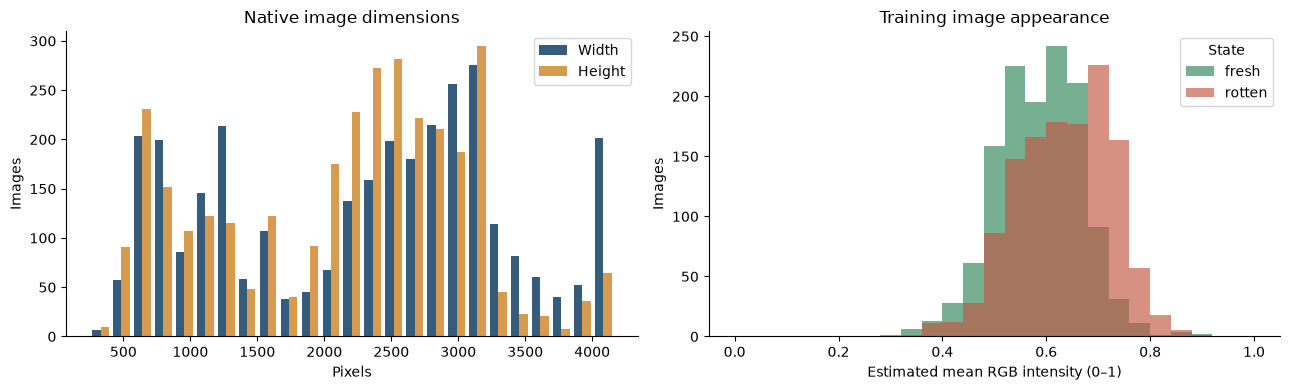

In [7]:
dimension_counts = image_info.groupby(["width", "height"]).size().sort_values(ascending=False)
display(image_info[["width", "height", "channels"]].describe())
display(image_info.groupby(["format", "mode", "channels"]).size().rename("images").to_frame())
print("Distinct native dimensions:", len(dimension_counts))
display(dimension_counts.head(10).rename("images").to_frame())

training_properties = audit.loc[audit["split"].eq("train") & audit["image_ok"]]
display(training_properties.groupby("state")["mean_rgb_intensity"].agg(["count", "mean", "std"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(
    [image_info["width"], image_info["height"]], bins=25,
    label=["Width", "Height"], color=["#355c7d", "#d79b50"],
)
axes[0].set(title="Native image dimensions", xlabel="Pixels", ylabel="Images")
axes[0].legend()
for state, colour in COLOURS.items():
    values = training_properties.loc[training_properties["state"].eq(state), "mean_rgb_intensity"]
    axes[1].hist(values, bins=np.linspace(0, 1, 26), alpha=0.65, label=state, color=colour)
axes[1].set(title="Training image appearance", xlabel="Estimated mean RGB intensity (0–1)", ylabel="Images")
axes[1].legend(title="State")
fig.tight_layout()
plt.show()


## 8. Dataset visualization

Display one fresh and one rotten **training image** for each of the eight fruits.
Selection is deterministic for seed 42 after sorting filenames. Readable training
rows are the only candidates. Images are displayed in RGB after EXIF orientation;
no illumination correction is applied.

Look for colour casts, uneven exposure, shadows, highlights, backgrounds and
framing. Use these training examples to guide later preprocessing choices.


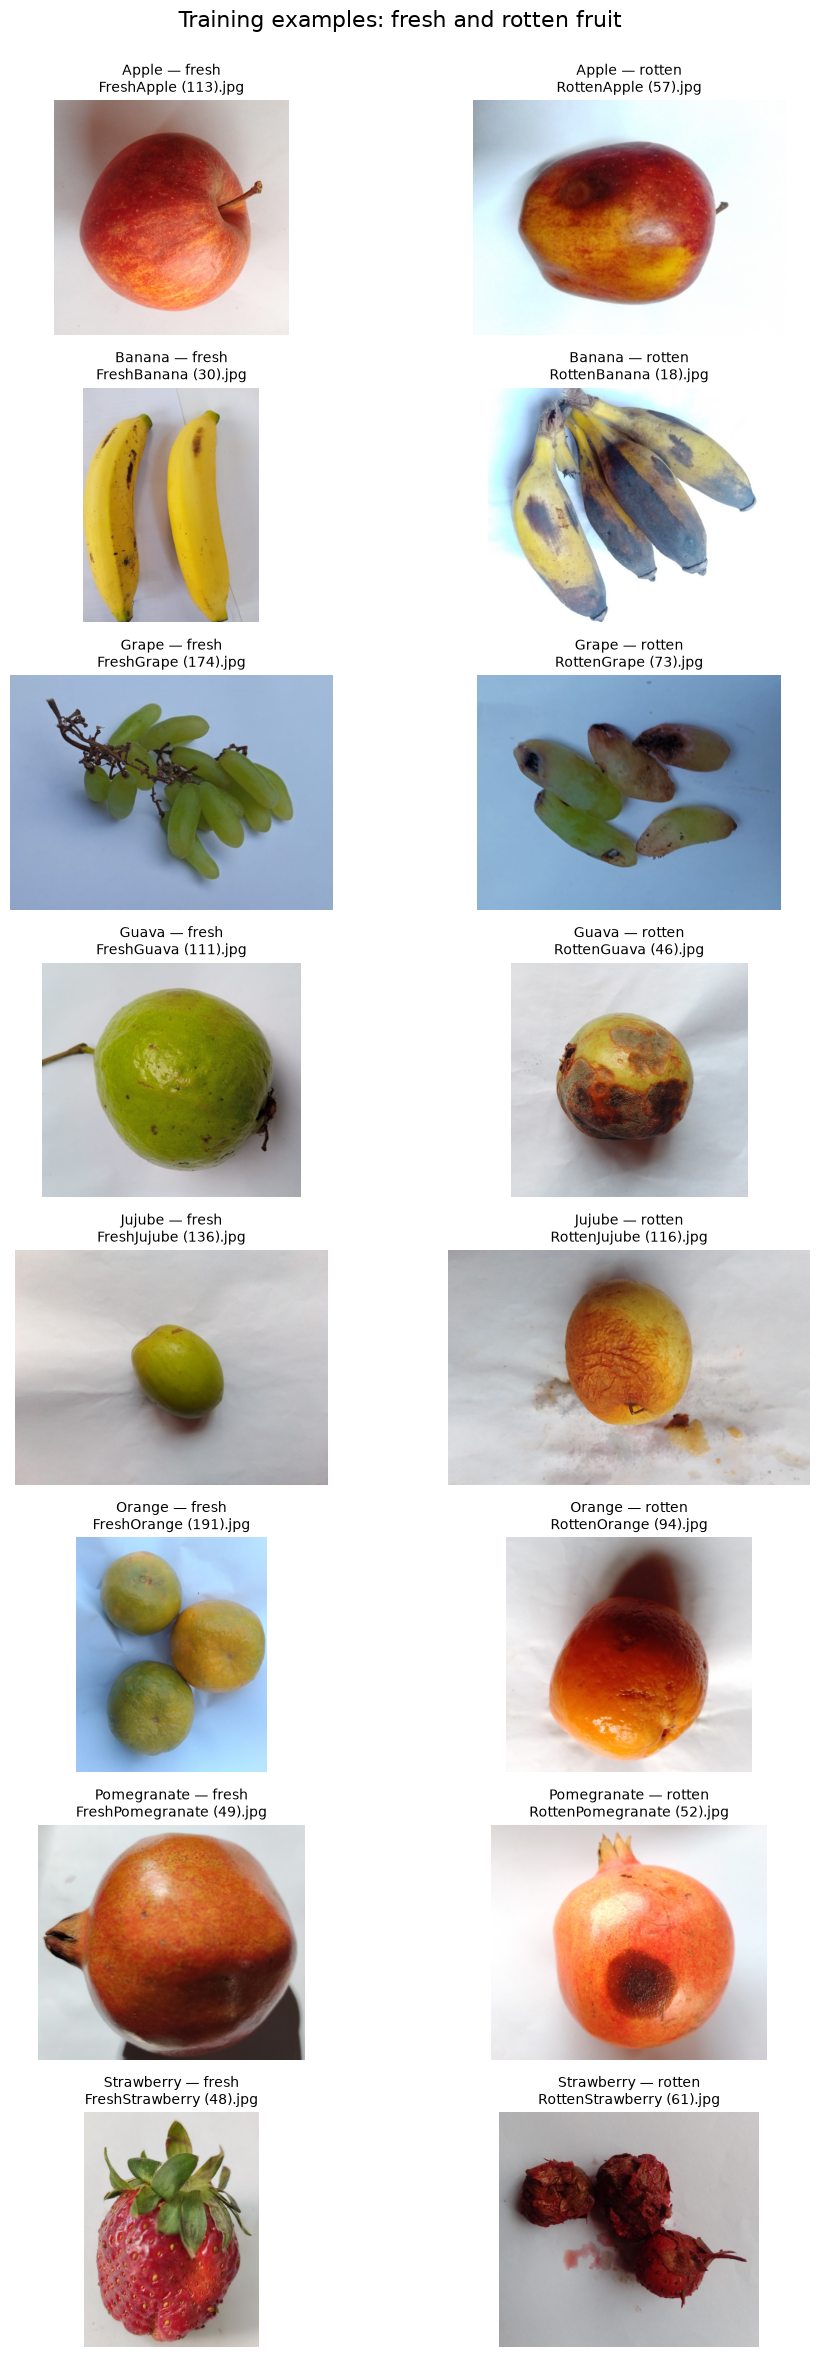

In [8]:
rng = np.random.default_rng(SEED)
sample_pool = audit.loc[audit["split"].eq("train") & audit["image_ok"]].sort_values("path")
sample_records = []
fig, axes = plt.subplots(len(FRUITS), 2, figsize=(10, 24), squeeze=False)
for fruit_index, fruit in enumerate(FRUITS):
    for state_index, state in enumerate(LABEL_NAMES.values()):
        ax = axes[fruit_index, state_index]
        candidates = sample_pool.loc[
            sample_pool["fruit"].eq(fruit) & sample_pool["state"].eq(state)
        ]
        ax.axis("off")
        if candidates.empty:
            ax.text(0.5, 0.5, "No readable training image", ha="center", va="center")
            ax.set_title(f"{fruit.title()} — {state}")
            continue
        chosen = candidates.iloc[int(rng.integers(len(candidates)))]
        with Image.open(chosen["_image_path"]) as image:
            preview = ImageOps.exif_transpose(image).convert("RGB")
            preview.thumbnail((640, 640))
            ax.imshow(preview)
        ax.set_title(f"{fruit.title()} — {state}\n{Path(chosen['path']).name}", fontsize=10)
        sample_records.append({
            "fruit": fruit, "state": state, "split": chosen["split"], "path": chosen["path"]
        })
fig.suptitle("Training examples: fresh and rotten fruit", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

selected_samples = pd.DataFrame(sample_records)


## 9. Observations

The summary below is calculated from this run. Record visual observations against
the training grid, and keep them separate from measured properties.

- **Lighting and shadows:** inspected training examples have light paper backgrounds
  with changing grey/blue casts, directional shadows and bright reflections on glossy
  fruit. These motivate testing illumination normalization; they do not establish its benefit.
- **Colour and appearance:** fresh and rotten examples differ in discoloration, spots
  and texture as well as natural fruit colour. Normalization should preserve these
  potentially useful class cues. Global intensity cannot separate them from lighting.
- **Background and framing:** training examples vary in fruit scale, cropping, orientation
  and number of fruits. Background and object coverage may act as classifier shortcuts.
- **Scope:** these are descriptive observations, not proof that illumination caused
  classification errors or that any normalization method will improve accuracy.

### Dataset limitations and next steps

1. Exact duplicate files across splits must be grouped into one split, or deduplicated,
   before fixing the manifest for final evaluation. Do not silently alter the CSV here.
2. Byte hashing misses some re-encoded copies and near-duplicate views. The manifest has
   no capture-session or physical-fruit identifier, so independence cannot be established
   from these columns alone.
3. Equal file counts do not measure diversity, label quality or coverage of real-world
   lighting. A 20-file test subset per fruit/state class limits detailed comparisons.
4. Image dimensions vary; later preprocessing must define a consistent resize/crop policy.
   Fit or choose data-dependent preprocessing with training/validation data, keeping the
   test split for final evaluation.
5. This notebook does not implement training. PyTorch availability and the model pipeline
   need their own checks when training is introduced.


In [9]:
readiness = pd.Series({
    "Manifest schema valid": bool(schema_checks.all()),
    "All image paths exist": missing_paths.empty,
    "No repeated resolved paths": repeated_paths.empty,
    "Every original image is listed": not unlisted_paths,
    "All files could be hashed": not hash_errors,
    "No exact duplicate contents across splits": not leaking_hashes,
    "Expected class and split counts": bool(
        len(df) == 3200 and class_counts.eq(200).all() and split_balance_ok
    ),
    "All images readable": integrity_issues.empty,
}, name="passed")
display(readiness.to_frame())
status = "All listed checks passed." if readiness.all() else "Review the failed checks before training."
display(Markdown(
    f"**Inspection status:** {status}\n\n"
    f"- Manifest: **{len(df):,} files**, **{df['cls'].nunique()} classes**.\n"
    f"- Split counts: **{split_counts['train']:,} / {split_counts['val']:,} / {split_counts['test']:,}**.\n"
    f"- Unique byte contents: **{df['sha256'].nunique():,}**.\n"
    f"- Exact duplicate groups: **{len(duplicate_summary)}**, including "
    f"**{len(leaking_hashes)}** spanning different splits.\n"
    f"- Missing/unreadable images: **{len(integrity_issues)}**.\n"
    f"- Native sizes: **{len(dimension_counts):,}** combinations; "
    f"width **{image_info['width'].min():,}–{image_info['width'].max():,} px**, "
    f"height **{image_info['height'].min():,}–{image_info['height'].max():,} px**.\n"
    f"- Visual examples: **{len(selected_samples)} training images**, seed **{SEED}**."
))


,passed
Manifest schema valid,True
All image paths exist,True
No repeated resolved paths,True
Every original image is listed,True
All files could be hashed,True
No exact duplicate contents across splits,False
Expected class and split counts,True
All images readable,True


**Inspection status:** Review the failed checks before training.

- Manifest: **3,200 files**, **16 classes**.
- Split counts: **2,560 / 320 / 320**.
- Unique byte contents: **3,193**.
- Exact duplicate groups: **7**, including **2** spanning different splits.
- Missing/unreadable images: **0**.
- Native sizes: **2,693** combinations; width **251–4,160 px**, height **301–4,160 px**.
- Visual examples: **16 training images**, seed **42**.